Dimensões do dataset: (61594, 5)

Primeiras avaliações:
        Time_submitted                                             Review  \
0  2022-07-09 15:00:00  Great music service, the audio is high quality...   
1  2022-07-09 14:21:22  Please ignore previous negative rating. This a...   
2  2022-07-09 13:27:32  This pop-up "Get the best Spotify experience o...   
3  2022-07-09 13:26:45    Really buggy and terrible to use as of recently   
4  2022-07-09 13:20:49  Dear Spotify why do I get songs that I didn't ...   

   Rating  Total_thumbsup Reply  
0       5               2   NaN  
1       5               1   NaN  
2       4               0   NaN  
3       1               1   NaN  
4       1               1   NaN  

Dimensões após preparação:
(61393, 5)

Distribuição dos sentimentos:
Sentiment
Positivo    29781
Negativo    24731
Neutro       6881
Name: count, dtype: int64

========== TEXTOS CONFLITANTES ==========
Quantidade de textos conflitantes: 11

Dimensões após remoção de conflitos

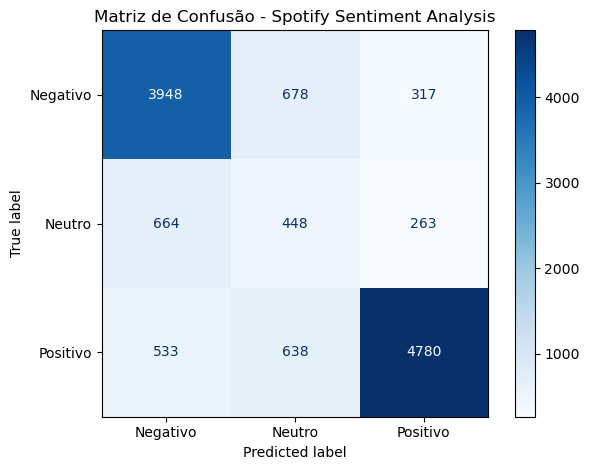


========== ERROS DO MODELO ==========
Quantidade de erros: 3093

Primeiros 20 erros:
                                                  Review Sentimento_Real  \
37725  It's the best out there. BUT... But I've seen ...          Neutro   
7489   Ok I love the app and all, but recently the ne...        Positivo   
20333                                    Too much ads fr        Negativo   
61131  The shuffle feature doesn't shuffle very well ...        Positivo   
40122  Nice app, but advisement interrupt more, make ...        Negativo   
57427  My podcast episodes have been scrambling up. O...          Neutro   
27797    It's good but there are lots of ads..........🙂🙁        Positivo   
51896  Edit Lossless audio. You're now behind. I'm ev...        Negativo   
26323  Great app, but adding songs to playlists is a ...        Positivo   
41682  It gets WAY to annoying when I'm trying to pla...          Neutro   
28712  Useless, I live in Quebec so cannot have premi...        Negativo   
12

In [ ]:
# ============================================
# 1. IMPORTAÇÃO DAS BIBLIOTECAS
# ============================================

import pandas as pd
import joblib
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.naive_bayes import MultinomialNB

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score
)

# ============================================
# 2. CARREGAMENTO DO DATASET
# ============================================

df = pd.read_csv(
    r"C:\Users\nando\Desktop\spotify-sentiment-analysis\dataset\reviews.csv"
)

print("Dimensões do dataset:", df.shape)

print("\nPrimeiras avaliações:")
print(df.head())


# ============================================
# 3. PREPARAÇÃO DOS DADOS
# ============================================

# Remover registros sem rating
df = df.dropna(subset=["Rating"])

# Garantir que os ratings sejam inteiros
df["Rating"] = df["Rating"].astype(int)

# Remover avaliações vazias
df = df.dropna(subset=["Review"])

df["Review"] = df["Review"].astype(str)

# Remover espaços desnecessários
df["Review"] = df["Review"].str.replace(
    r"\s+",
    " ",
    regex=True
).str.strip()

# Remover avaliações vazias
df = df[df["Review"] != ""]

# Manter somente ratings válidos
df = df[df["Rating"].between(1, 5)].copy()

# Remover duplicatas exatas de texto e rating
df = df.drop_duplicates(subset=["Review", "Rating"])

print("\nDimensões após preparação:")
print(df.shape)


# ============================================
# 4. CLASSIFICAÇÃO DOS SENTIMENTOS
# ============================================

def classificar_sentimento(rating):

    if rating <= 2:
        return "Negativo"

    elif rating == 3:
        return "Neutro"

    else:
        return "Positivo"


df["Sentiment"] = df["Rating"].apply(classificar_sentimento)


# Visualizar distribuição das classes

print("\nDistribuição dos sentimentos:")
print(df["Sentiment"].value_counts())


# ============================================
# 5. VERIFICAÇÃO DE TEXTOS CONFLITANTES
# ============================================

# Identificar textos associados a diferentes sentimentos

conflitos = df.groupby("Review")["Sentiment"].nunique()

reviews_conflitantes = conflitos[conflitos > 1]

print("\n========== TEXTOS CONFLITANTES ==========")

print("Quantidade de textos conflitantes:", len(reviews_conflitantes))

# Remover textos associados a sentimentos diferentes

reviews_validas = conflitos[conflitos == 1].index

df = df[df["Review"].isin(reviews_validas)].copy()

# Remover duplicatas restantes pelo texto

df = df.drop_duplicates(subset=["Review"])

print("\nDimensões após remoção de conflitos:")
print(df.shape)


# ============================================
# 6. SEPARAÇÃO DAS VARIÁVEIS
# ============================================

X = df["Review"]
y = df["Sentiment"]


# ============================================
# 7. DIVISÃO DOS DADOS
# ============================================

X_train, X_test, y_train_sentiment, y_test_sentiment = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\n========== DIVISÃO DOS DADOS ==========")

print("Quantidade de dados para treinamento:", len(X_train))
print("Quantidade de dados para teste:", len(X_test))


# ============================================
# 8. CRIAÇÃO DO PIPELINE
# ============================================

# Stopwords preservando negações

stopwords_personalizadas = list(
    ENGLISH_STOP_WORDS.difference({
        "not",
        "no",
        "nor",
        "never",
        "neither",
        "but",
        "however",
        "although",
        "though",
        "yet"
    })
)

modelo_sentiment = Pipeline([

    # Transformação dos textos em vetores numéricos
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        stop_words=stopwords_personalizadas,
        max_features=10000,
        ngram_range=(1, 2),
        sublinear_tf=True,
        token_pattern=r"(?u)\b\w[\w']+\b"
    )),

    # Classificador Naive Bayes
    ("naive_bayes", MultinomialNB())

])


# ============================================
# 9. OTIMIZAÇÃO DOS HIPERPARÂMETROS
# ============================================

parametros = {

    "tfidf__min_df": [1, 2, 3],

    "tfidf__max_df": [0.95, 1.0],

    "naive_bayes__alpha": [0.1, 0.5, 1.0, 2.0],

    "naive_bayes__fit_prior": [True, False]

}

grid_search = GridSearchCV(

    estimator=modelo_sentiment,

    param_grid=parametros,

    scoring="f1_macro",

    cv=5,

    n_jobs=-1,

    verbose=1

)

# Executar otimização

grid_search.fit(
    X_train,
    y_train_sentiment
)


# Selecionar o melhor modelo

modelo_sentiment = grid_search.best_estimator_


print("\n========== MELHOR CONFIGURAÇÃO ==========")

print("Melhores parâmetros:")
print(grid_search.best_params_)

print("\nMelhor F1 Macro na validação cruzada:")
print(f"{grid_search.best_score_:.4f}")

print("\nModelo otimizado com sucesso!")


# ============================================
# 10. REALIZAÇÃO DAS PREVISÕES
# ============================================

pred_sentiment = modelo_sentiment.predict(X_test)


# ============================================
# 11. AVALIAÇÃO DO MODELO
# ============================================

accuracy = accuracy_score(
    y_test_sentiment,
    pred_sentiment
)

f1_macro = f1_score(
    y_test_sentiment,
    pred_sentiment,
    average="macro"
)

f1_weighted = f1_score(
    y_test_sentiment,
    pred_sentiment,
    average="weighted"
)


print("\n========== RESULTADOS ==========")

print(f"Accuracy: {accuracy:.4f}")

print(f"F1 Macro: {f1_macro:.4f}")

print(f"F1 Weighted: {f1_weighted:.4f}")


print("\nClassification Report:")

print(classification_report(
    y_test_sentiment,
    pred_sentiment,
    zero_division=0
))


# ============================================
# 12. MATRIZ DE CONFUSÃO
# ============================================

labels = ["Negativo", "Neutro", "Positivo"]

matriz = confusion_matrix(
    y_test_sentiment,
    pred_sentiment,
    labels=labels
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=labels
)

disp.plot(cmap="Blues")

plt.title("Matriz de Confusão - Spotify Sentiment Analysis")

plt.tight_layout()

plt.show()


# ============================================
# 13. ANÁLISE DOS ERROS
# ============================================

erros = pd.DataFrame({

    "Review": X_test,

    "Sentimento_Real": y_test_sentiment,

    "Sentimento_Previsto": pred_sentiment

})

# Filtrar somente classificações incorretas

erros = erros[
    erros["Sentimento_Real"] != erros["Sentimento_Previsto"]
]

print("\n========== ERROS DO MODELO ==========")

print("Quantidade de erros:", len(erros))

print("\nPrimeiros 20 erros:")

print(erros.head(20))


# ============================================
# 14. SALVAMENTO DO MODELO
# ============================================

joblib.dump(
    modelo_sentiment,
    "spotify_sentiment_model.pkl"
)

print("\nModelo salvo com sucesso!")


# ============================================
# 15. TESTE COM NOVAS AVALIAÇÕES
# ============================================

avaliacoes = [

    "Spotify is amazing! I love listening to music here.",

    "Spotify keeps crashing. This is very disappointing.",

    "The app is okay, nothing special.",

    "I don't like Spotify anymore.",

    "The music selection is good, but the interface could be better.",

    "I love the music but hate the ads.",

    "Spotify is not bad.",

    "This app is absolutely terrible."

]


print("\n========== TESTE DE NOVAS AVALIAÇÕES ==========")


for i, texto in enumerate(avaliacoes, start=1):

    # Previsão do sentimento
    previsao = modelo_sentiment.predict([texto])[0]

    # Probabilidades por classe
    probabilidades = modelo_sentiment.predict_proba([texto])[0]

    print(f"\nAVALIAÇÃO {i}")

    print("-" * 50)

    print("Texto:", texto)

    print("Sentimento previsto:", previsao)

    print("\nProbabilidades:")

    for classe, probabilidade in zip(
        modelo_sentiment.classes_,
        probabilidades
    ):

        print(f"{classe}: {probabilidade:.2%}")